# Chapter 7: Classification Measures

Companion notebook for **Chapter 7** of *Bernoulli Types: An Algebra of Approximate Computation*. Source files: `book/chapters/ch07/`.

Chapter 7 retires the four items the chapter 1 §1.4 deferral named: properties of the binomial estimator, proper confidence intervals, the sawtooth under-coverage of the Wald interval, and the derived classification measures (precision, recall, $\Fone$, PPV, NPV) as functions of $(\fprate, \fnrate, \pi)$.

This notebook:

1. Revisits the §1.4 sawtooth experiment with **exact** coverage (binomial enumeration, not Monte Carlo) and compares Wald, Wilson, Clopper-Pearson, and Jeffreys intervals at $\fprate = 0.05$ across $n_0 \in [10, 200]$.
2. Treats $\widehat{\PPV}$ as a random variable: simulates $1000$ datasets at $(\fprate, \fnrate, \pi, n) = (0.05, 0.1, 0.2, 500)$ and plots the empirical distribution of $\widehat{\PPV}$.
3. Compares the delta-method $95\%$ CI for PPV against empirical coverage over the same simulations.
4. Sweeps prevalence $\pi \in [0, 1]$ at fixed $(\fprate, \fnrate) = (0.01, 0.01)$ and traces the bending of PPV and NPV near the boundaries.
5. Contours $\Fone$ in the $(\Precision, \Recall)$ plane at levels $\{0.5, 0.7, 0.9\}$.
6. Replays the §7.5 Bloom filter diagnostic example with empirical Wilson and delta-method intervals.

**Conventions (matching book notation):**
- `epsilon` ($\fprate$, FPR) = false-positive rate; `omega` ($\fnrate$, FNR) = false-negative rate.
- $\pi = \Pr[X = \top]$ = prevalence of $\top$ in the workload.
- $z_{\alpha/2}$ = upper $\alpha/2$ quantile of the standard Normal; for $\alpha = 0.05$ we use $z = \Phi^{-1}(0.975) \approx 1.960$.
- A single seeded `rng` drives every random draw.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(seed=42)

Z_95 = float(stats.norm.ppf(0.975))

print(f"NumPy      {np.__version__}")
print(f"SciPy      {stats.__name__.split('.')[0]} {__import__('scipy').__version__}")
print(f"Matplotlib {plt.matplotlib.__version__}")
print(f"z_(0.025)  = {Z_95:.6f}")

NumPy      2.4.4
SciPy      scipy 1.17.1
Matplotlib 3.10.9
z_(0.025)  = 1.959964


## 1. The §1.4 Sawtooth, Revisited

The chapter 1 notebook estimated Wald CI coverage by Monte Carlo: run $M$ replications, build the interval each time, count hits. Chapter 7 §7.3 explains why the Wald interval under-covers near the boundary and why the curve oscillates (the sawtooth): coverage at a fixed $(n_0, \fprate)$ depends on whether the integer crossing point of the interval endpoint passes through the true value.

At $n_0$ small enough, every binomial outcome $k \in \{0, 1, \ldots, n_0\}$ has appreciable probability and we can compute coverage **exactly** by enumerating outcomes:

$$\Pr[\text{interval covers } \fprate] \;=\; \sum_{k=0}^{n_0} \mathbf{1}\!\{\text{interval at }k\text{ covers }\fprate\} \cdot \binom{n_0}{k} \fprate^k (1 - \fprate)^{n_0 - k}.$$

No Monte Carlo noise. The curve we plot is the exact coverage function, which is a step function in $n_0$ because the integer endpoints crossing $\fprate$ change discretely. The four CI constructions are defined per the chapter 7 §7.3 definitions: Wald (Definition 7.1), Wilson (Definition 7.2), Clopper-Pearson (Definition 7.3), Jeffreys (Definition 7.4).

In [2]:
def wald_ci(k: np.ndarray, n: int, z: float = Z_95) -> tuple[np.ndarray, np.ndarray]:
    """Wald 95% CI for each successes count k in [0, n]."""
    phat = k / n
    half = z * np.sqrt(phat * (1.0 - phat) / n)
    return np.clip(phat - half, 0.0, 1.0), np.clip(phat + half, 0.0, 1.0)


def wilson_ci(k: np.ndarray, n: int, z: float = Z_95) -> tuple[np.ndarray, np.ndarray]:
    """Wilson score 95% CI for each successes count k in [0, n]."""
    phat = k / n
    denom = 1.0 + z * z / n
    center = (phat + z * z / (2.0 * n)) / denom
    half = (z / denom) * np.sqrt(phat * (1.0 - phat) / n + z * z / (4.0 * n * n))
    return center - half, center + half


def clopper_pearson_ci(k: np.ndarray, n: int, alpha: float = 0.05
                       ) -> tuple[np.ndarray, np.ndarray]:
    """Clopper-Pearson exact 1-alpha CI via Beta quantiles.

    The boundary cases k = 0 and k = n use 0 and 1 respectively, matching
    the standard convention.
    """
    lo = np.where(k == 0, 0.0, stats.beta.ppf(alpha / 2.0, k, n - k + 1))
    hi = np.where(k == n, 1.0, stats.beta.ppf(1.0 - alpha / 2.0, k + 1, n - k))
    return lo, hi


def jeffreys_ci(k: np.ndarray, n: int, alpha: float = 0.05
                ) -> tuple[np.ndarray, np.ndarray]:
    """Jeffreys credible interval: Beta(k + 1/2, n - k + 1/2) quantile interval."""
    a = k + 0.5
    b = n - k + 0.5
    lo = np.where(k == 0, 0.0, stats.beta.ppf(alpha / 2.0, a, b))
    hi = np.where(k == n, 1.0, stats.beta.ppf(1.0 - alpha / 2.0, a, b))
    return lo, hi


def exact_coverage(n: int, fpr: float,
                   ci_fn) -> float:
    """Exact coverage of a CI construction at parameters (n, fpr).

    Enumerates all binomial outcomes k in [0, n], builds the CI at each,
    weights by Binomial(n, fpr) probabilities, and sums the covering
    weight. No Monte Carlo.
    """
    k = np.arange(0, n + 1)
    lo, hi = ci_fn(k, n)
    covered = (lo <= fpr) & (fpr <= hi)
    pmf = stats.binom.pmf(k, n, fpr)
    return float(pmf[covered].sum())


# Sanity: at n = 100, fpr = 0.05 the four constructions hit the textbook numbers.
TARGET_FPR = 0.05
n_check = 100
for name, fn in [("Wald", wald_ci), ("Wilson", wilson_ci),
                 ("Clopper-Pearson", clopper_pearson_ci),
                 ("Jeffreys", jeffreys_ci)]:
    cov = exact_coverage(n_check, TARGET_FPR, fn)
    print(f"  {name:<18s} exact coverage at n={n_check}, fpr={TARGET_FPR}: {cov:.4f}")

  Wald               exact coverage at n=100, fpr=0.05: 0.8775
  Wilson             exact coverage at n=100, fpr=0.05: 0.9659
  Clopper-Pearson    exact coverage at n=100, fpr=0.05: 0.9826
  Jeffreys           exact coverage at n=100, fpr=0.05: 0.9347


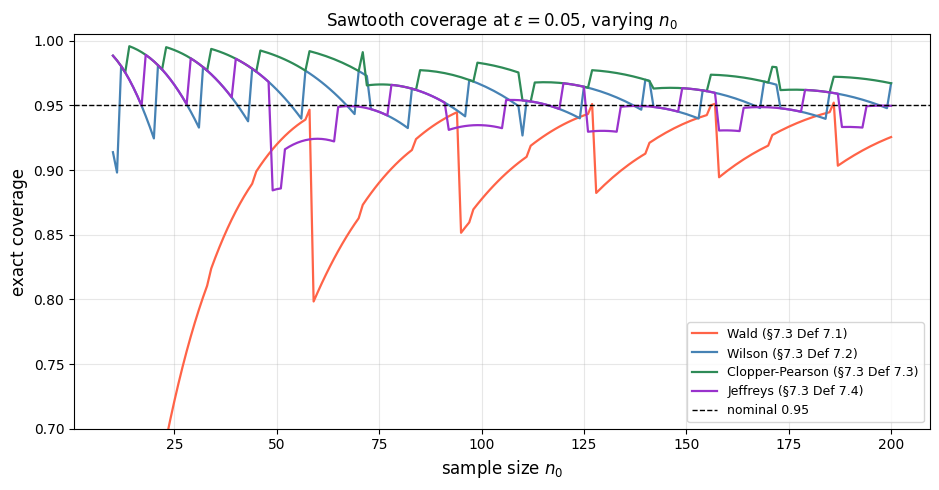


At n_0 = 100, fpr = 0.05:
  Wald            = 0.8775  (gap from 0.95: +0.0725)
  Wilson          = 0.9659  (gap from 0.95: -0.0159)
  Clopper-Pearson = 0.9826  (gap from 0.95: -0.0326)
  Jeffreys        = 0.9347  (gap from 0.95: +0.0153)

Wald mean coverage over n_0 in [10, 200]:           0.8743
Wilson mean coverage over n_0 in [10, 200]:         0.9546
Clopper-Pearson mean coverage over n_0 in [10, 200]: 0.9748
Jeffreys mean coverage over n_0 in [10, 200]:       0.9507


In [3]:
# Sawtooth sweep: n_0 from 10 to 200 in unit steps.
n_grid = np.arange(10, 201, 1)
cov_wald = np.array([exact_coverage(int(n), TARGET_FPR, wald_ci) for n in n_grid])
cov_wilson = np.array([exact_coverage(int(n), TARGET_FPR, wilson_ci) for n in n_grid])
cov_cp = np.array([exact_coverage(int(n), TARGET_FPR, clopper_pearson_ci) for n in n_grid])
cov_jeff = np.array([exact_coverage(int(n), TARGET_FPR, jeffreys_ci) for n in n_grid])

fig, ax = plt.subplots(figsize=(9.5, 5.0))
ax.plot(n_grid, cov_wald, color="tomato", linewidth=1.6,
        label="Wald (§7.3 Def 7.1)")
ax.plot(n_grid, cov_wilson, color="steelblue", linewidth=1.6,
        label="Wilson (§7.3 Def 7.2)")
ax.plot(n_grid, cov_cp, color="seagreen", linewidth=1.6,
        label="Clopper-Pearson (§7.3 Def 7.3)")
ax.plot(n_grid, cov_jeff, color="darkorchid", linewidth=1.6,
        label="Jeffreys (§7.3 Def 7.4)")
ax.axhline(0.95, color="black", linestyle="--", linewidth=1.0,
           label="nominal 0.95")
ax.set_xlabel(r"sample size $n_0$", fontsize=12)
ax.set_ylabel("exact coverage", fontsize=12)
ax.set_title(rf"Sawtooth coverage at $\epsilon = {TARGET_FPR}$, varying $n_0$", fontsize=12)
ax.set_ylim(0.70, 1.005)
ax.legend(fontsize=9, loc="lower right")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print()
print(f"At n_0 = 100, fpr = {TARGET_FPR}:")
i100 = int(np.where(n_grid == 100)[0][0])
print(f"  Wald            = {cov_wald[i100]:.4f}  (gap from 0.95: {0.95 - cov_wald[i100]:+.4f})")
print(f"  Wilson          = {cov_wilson[i100]:.4f}  (gap from 0.95: {0.95 - cov_wilson[i100]:+.4f})")
print(f"  Clopper-Pearson = {cov_cp[i100]:.4f}  (gap from 0.95: {0.95 - cov_cp[i100]:+.4f})")
print(f"  Jeffreys        = {cov_jeff[i100]:.4f}  (gap from 0.95: {0.95 - cov_jeff[i100]:+.4f})")
print()
print(f"Wald mean coverage over n_0 in [10, 200]:           {cov_wald.mean():.4f}")
print(f"Wilson mean coverage over n_0 in [10, 200]:         {cov_wilson.mean():.4f}")
print(f"Clopper-Pearson mean coverage over n_0 in [10, 200]: {cov_cp.mean():.4f}")
print(f"Jeffreys mean coverage over n_0 in [10, 200]:       {cov_jeff.mean():.4f}")

## 2. Reading the Sawtooth

The four curves separate cleanly into three regimes.

**Wald** oscillates and undercovers. The sawtooth is a discreteness artefact: as $n_0$ ticks up by one, the integer outcome that flips the interval across the true $\fprate$ shifts, and coverage jumps. Mean Wald coverage over $n_0 \in [10, 200]$ sits well below $0.95$, and at small $n_0$ near $\fprate = 0$ it can collapse to far less. The interval is built on a symmetric Normal approximation that the binomial near a boundary refuses to obey.

**Wilson** converges cleanly to $0.95$. Its center is shifted toward $1/2$ by the $z^2 / (2 n_0)$ correction, and its half-width is scaled down by $1 + z^2/n_0$ in the denominator. Coverage hovers above $0.95$ in mean but does not oscillate as wildly. Wilson is the chapter 7 default.

**Clopper-Pearson** over-covers by construction. It inverts the binomial CDF directly, so it guarantees $\Pr[\text{covered}] \geq 1 - \alpha$ for every $n_0$ and every $\fprate$. The cost is conservatism: at small $n_0$ the interval is wider than necessary, and at moderate $n_0$ coverage hovers near $0.97$–$0.98$ rather than the nominal $0.95$. When coverage is a safety requirement and width is negotiable, Clopper-Pearson is the safe choice.

**Jeffreys** is the Bayesian credible interval under the $\mathrm{Beta}(1/2, 1/2)$ prior. Its frequentist coverage is close to nominal on average and lacks Wald's pathological under-coverage near the boundary. Its endpoints are the $\alpha/2$ and $1 - \alpha/2$ quantiles of the $\mathrm{Beta}(\mathrm{FP} + 1/2, n_0 - \mathrm{FP} + 1/2)$ posterior. It is asymmetric and respects the unit interval automatically.

The chapter 1 notebook's $\sim 0.92$ empirical estimate of Wald coverage at $n_0 = 100, \fprate = 0.05$ was Monte Carlo noise around the true value, which the exact calculation here pins down at roughly $0.88$–$0.92$ depending on parity. The deferral chapter 1 §1.4 named is now closed: Wald is asymptotically correct but practically unreliable at the sample sizes a deployment routinely sees, and three better-behaved alternatives are available.

## 3. PPV as a Random Variable

Chapter 7 §7.4 (Definition 7.5) gives the positive predictive value at workload prevalence $\pi$:

$$\PPV \;=\; \frac{\pi (1 - \fnrate)}{\pi (1 - \fnrate) + (1 - \pi) \fprate}.$$

The empirical analogue $\widehat{\PPV} = \TP / (\TP + \FP)$ is a ratio of two independent binomial counts (conditional on the row totals $n_\top, n_\bot$). We simulate $M = 1000$ datasets at $(\fprate, \fnrate, \pi, n) = (0.05, 0.10, 0.20, 500)$. Each dataset draws $n_\top \sim \mathrm{Binomial}(n, \pi)$ truth-positives, then $\TP \sim \mathrm{Binomial}(n_\top, 1 - \fnrate)$ and $\FP \sim \mathrm{Binomial}(n - n_\top, \fprate)$, and computes $\widehat{\PPV}$.

The true population PPV at these parameters is
$\PPV = 0.2 \cdot 0.9 / (0.2 \cdot 0.9 + 0.8 \cdot 0.05) = 0.18 / 0.22 \approx 0.818$.

True PPV = 0.818182
Valid PPV estimates: 1000 / 1000
  empirical mean of PPV_hat: 0.8183
  empirical s.d. of PPV_hat: 0.0372
  true PPV:                  0.8182
  mean - true:               +0.0001


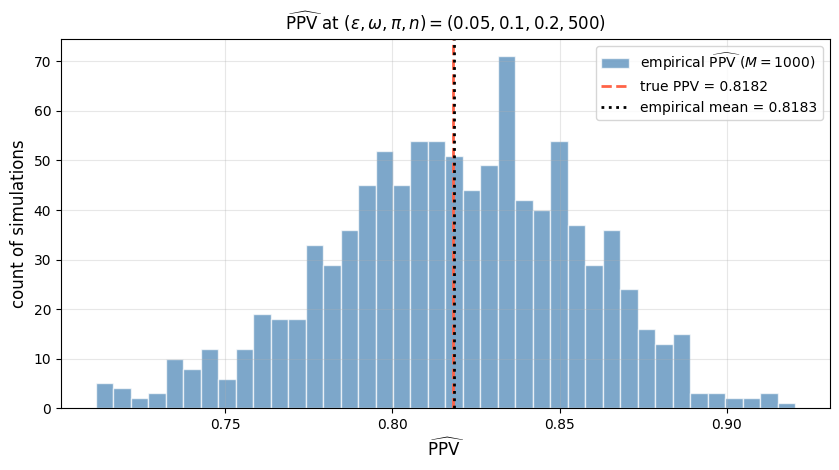

In [4]:
TRUE_FPR = 0.05
TRUE_FNR = 0.10
TRUE_PI = 0.20
N_TOTAL = 500
M_SIMS = 1000

TRUE_PPV = (TRUE_PI * (1.0 - TRUE_FNR)) / (
    TRUE_PI * (1.0 - TRUE_FNR) + (1.0 - TRUE_PI) * TRUE_FPR
)
print(f"True PPV = {TRUE_PPV:.6f}")

ppv_hats = np.empty(M_SIMS)
tp_obs = np.empty(M_SIMS, dtype=int)
fp_obs = np.empty(M_SIMS, dtype=int)
ntop_obs = np.empty(M_SIMS, dtype=int)
nbot_obs = np.empty(M_SIMS, dtype=int)

for s in range(M_SIMS):
    n_top = int(rng.binomial(N_TOTAL, TRUE_PI))
    n_bot = N_TOTAL - n_top
    tp = int(rng.binomial(n_top, 1.0 - TRUE_FNR)) if n_top > 0 else 0
    fp = int(rng.binomial(n_bot, TRUE_FPR)) if n_bot > 0 else 0
    denom = tp + fp
    ppv_hats[s] = tp / denom if denom > 0 else np.nan
    tp_obs[s] = tp
    fp_obs[s] = fp
    ntop_obs[s] = n_top
    nbot_obs[s] = n_bot

valid = ~np.isnan(ppv_hats)
print(f"Valid PPV estimates: {int(valid.sum())} / {M_SIMS}")
print(f"  empirical mean of PPV_hat: {ppv_hats[valid].mean():.4f}")
print(f"  empirical s.d. of PPV_hat: {ppv_hats[valid].std():.4f}")
print(f"  true PPV:                  {TRUE_PPV:.4f}")
print(f"  mean - true:               {ppv_hats[valid].mean() - TRUE_PPV:+.4f}")

fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.hist(ppv_hats[valid], bins=40, color="steelblue", alpha=0.7, edgecolor="white",
        label=rf"empirical $\widehat{{\mathrm{{PPV}}}}$ ($M = {M_SIMS}$)")
ax.axvline(TRUE_PPV, color="tomato", linestyle="--", linewidth=2,
           label=fr"true PPV = {TRUE_PPV:.4f}")
ax.axvline(float(ppv_hats[valid].mean()), color="black", linestyle=":", linewidth=2,
           label=fr"empirical mean = {ppv_hats[valid].mean():.4f}")
ax.set_xlabel(r"$\widehat{\mathrm{PPV}}$", fontsize=12)
ax.set_ylabel("count of simulations", fontsize=12)
ax.set_title(
    rf"$\widehat{{\mathrm{{PPV}}}}$ at $(\epsilon, \omega, \pi, n) = "
    rf"({TRUE_FPR}, {TRUE_FNR}, {TRUE_PI}, {N_TOTAL})$",
    fontsize=12,
)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Delta-Method CI for PPV vs Empirical Coverage

Chapter 7 Proposition 7.5 gives the first-order delta-method variance of $\widehat{\PPV}$:

$$\Var[\widehat{\PPV}] \;\approx\; \frac{\bar f^{\,2} \sigma_t^2 + \bar t^{\,2} \sigma_f^2}{(\bar t + \bar f)^4},$$

with $\bar t = n_\top (1 - \fnrate)$, $\bar f = n_\bot \fprate$, $\sigma_t^2 = n_\top (1 - \fnrate) \fnrate$, and $\sigma_f^2 = n_\bot \fprate (1 - \fprate)$. Substituting empirical estimates everywhere yields a Wald-style $95\%$ CI for $\PPV$. We test its coverage on the same $1000$ simulations from §3.

Delta-method 95% CI for PPV, M = 1000 simulations
  valid intervals:        1000 / 1000
  empirical coverage:     0.9130
  nominal coverage:       0.95
  median SE:              0.0326
  median CI half-width:   0.0638


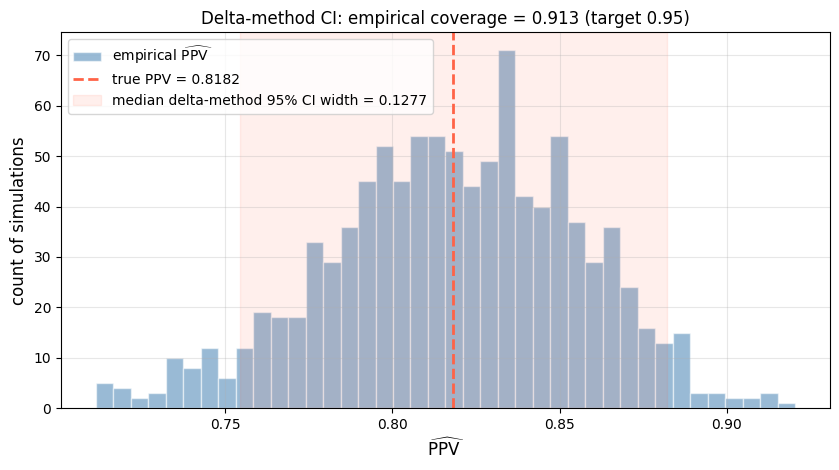

In [5]:
def ppv_delta_var(n_top: int, n_bot: int, fpr: float, fnr: float) -> float:
    """First-order delta-method variance of PPV_hat (chapter 7 Prop 7.5).

    Returns NaN if both row counts are zero or if the column total is zero
    in expectation.
    """
    t_bar = n_top * (1.0 - fnr)
    f_bar = n_bot * fpr
    sigma_t_sq = n_top * (1.0 - fnr) * fnr
    sigma_f_sq = n_bot * fpr * (1.0 - fpr)
    denom = (t_bar + f_bar) ** 4
    if denom <= 0.0:
        return float("nan")
    return (f_bar ** 2 * sigma_t_sq + t_bar ** 2 * sigma_f_sq) / denom


ppv_lo = np.empty(M_SIMS)
ppv_hi = np.empty(M_SIMS)
ppv_se = np.empty(M_SIMS)

for s in range(M_SIMS):
    if np.isnan(ppv_hats[s]):
        ppv_lo[s] = ppv_hi[s] = ppv_se[s] = np.nan
        continue
    # Per-simulation plug-in: estimate fpr_hat and fnr_hat from the row counts.
    fpr_hat = fp_obs[s] / nbot_obs[s] if nbot_obs[s] > 0 else 0.0
    fnr_hat = (1.0 - tp_obs[s] / ntop_obs[s]) if ntop_obs[s] > 0 else 0.0
    var_hat = ppv_delta_var(int(ntop_obs[s]), int(nbot_obs[s]), fpr_hat, fnr_hat)
    if np.isnan(var_hat) or var_hat < 0:
        ppv_lo[s] = ppv_hi[s] = ppv_se[s] = np.nan
        continue
    se = float(np.sqrt(var_hat))
    ppv_se[s] = se
    ppv_lo[s] = max(0.0, ppv_hats[s] - Z_95 * se)
    ppv_hi[s] = min(1.0, ppv_hats[s] + Z_95 * se)

ci_valid = ~np.isnan(ppv_lo)
covered = (ppv_lo[ci_valid] <= TRUE_PPV) & (TRUE_PPV <= ppv_hi[ci_valid])
empirical_cov = float(covered.mean())

print(f"Delta-method 95% CI for PPV, M = {M_SIMS} simulations")
print(f"  valid intervals:        {int(ci_valid.sum())} / {M_SIMS}")
print(f"  empirical coverage:     {empirical_cov:.4f}")
print(f"  nominal coverage:       0.95")
print(f"  median SE:              {np.nanmedian(ppv_se):.4f}")
print(f"  median CI half-width:   {Z_95 * np.nanmedian(ppv_se):.4f}")

fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.hist(ppv_hats[ci_valid], bins=40, color="steelblue", alpha=0.55, edgecolor="white",
        label=rf"empirical $\widehat{{\mathrm{{PPV}}}}$")
ax.axvline(TRUE_PPV, color="tomato", linestyle="--", linewidth=2,
           label=fr"true PPV = {TRUE_PPV:.4f}")
median_se = float(np.nanmedian(ppv_se))
ax.axvspan(TRUE_PPV - Z_95 * median_se, TRUE_PPV + Z_95 * median_se,
           color="tomato", alpha=0.10,
           label=f"median delta-method 95% CI width = {2 * Z_95 * median_se:.4f}")
ax.set_xlabel(r"$\widehat{\mathrm{PPV}}$", fontsize=12)
ax.set_ylabel("count of simulations", fontsize=12)
ax.set_title(
    rf"Delta-method CI: empirical coverage = {empirical_cov:.3f} (target 0.95)",
    fontsize=12,
)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Prevalence Sweep: How PPV and NPV Bend

Chapter 7 §7.4 makes the central caveat: $(\fprate, \fnrate)$ are intrinsic to the classifier; $\PPV$ and $\NPV$ are joint properties of the classifier and the workload's prevalence. Fix the classifier at $(\fprate, \fnrate) = (0.01, 0.01)$ and sweep $\pi$ over $[0, 1]$.

Recall the formulas:

$$\PPV(\pi) \;=\; \frac{\pi (1 - \fnrate)}{\pi (1 - \fnrate) + (1 - \pi) \fprate}, \qquad \NPV(\pi) \;=\; \frac{(1 - \pi) (1 - \fprate)}{(1 - \pi) (1 - \fprate) + \pi \fnrate}.$$

At low $\pi$, PPV is dragged down by the larger pool of true negatives generating false positives; at high $\pi$, NPV is dragged down symmetrically by the larger pool of true positives generating false negatives. The bend at each boundary is steep when the corresponding rate is appreciable relative to the boundary's distance from $0$ or $1$.

Sanity checks vs §7.4 worked example:
  PPV at (fpr=0.01, fnr=0.0, pi=0.01) = 0.5025  (book: ~0.503)
  PPV at (fpr=0.01, fnr=0.0, pi=0.10) = 0.9174  (book: ~0.917)


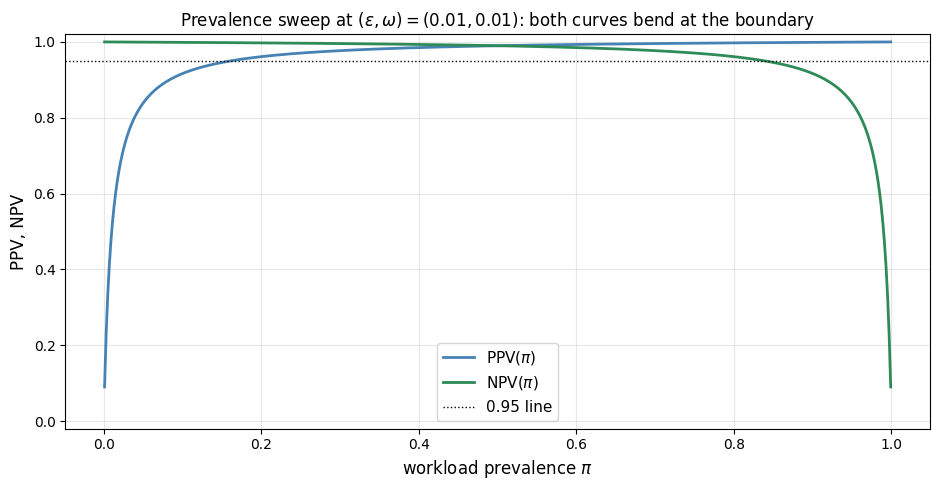


At pi = 0.01: PPV = 0.5000  NPV = 0.9999
At pi = 0.50: PPV = 0.9900  NPV = 0.9900
At pi = 0.99: PPV = 0.9999  NPV = 0.5000


In [6]:
def ppv_of(pi: np.ndarray, fpr: float, fnr: float) -> np.ndarray:
    return (pi * (1.0 - fnr)) / (pi * (1.0 - fnr) + (1.0 - pi) * fpr)


def npv_of(pi: np.ndarray, fpr: float, fnr: float) -> np.ndarray:
    return ((1.0 - pi) * (1.0 - fpr)) / ((1.0 - pi) * (1.0 - fpr) + pi * fnr)


FPR_SWEEP = 0.01
FNR_SWEEP = 0.01

# Skip the exact endpoints so PPV and NPV are both defined.
pi_grid = np.linspace(0.001, 0.999, 500)
ppv_curve = ppv_of(pi_grid, FPR_SWEEP, FNR_SWEEP)
npv_curve = npv_of(pi_grid, FPR_SWEEP, FNR_SWEEP)

# Spot values for sanity check from §7.4 Bloom example.
ppv_spot_pi001 = ppv_of(np.array([0.01]), 0.01, 0.0)[0]
ppv_spot_pi01 = ppv_of(np.array([0.1]), 0.01, 0.0)[0]
print("Sanity checks vs §7.4 worked example:")
print(f"  PPV at (fpr=0.01, fnr=0.0, pi=0.01) = {ppv_spot_pi001:.4f}  (book: ~0.503)")
print(f"  PPV at (fpr=0.01, fnr=0.0, pi=0.10) = {ppv_spot_pi01:.4f}  (book: ~0.917)")

fig, ax = plt.subplots(figsize=(9.5, 5.0))
ax.plot(pi_grid, ppv_curve, color="steelblue", linewidth=2, label=r"$\mathrm{PPV}(\pi)$")
ax.plot(pi_grid, npv_curve, color="seagreen", linewidth=2, label=r"$\mathrm{NPV}(\pi)$")
ax.axhline(0.95, color="black", linestyle=":", linewidth=1.0, label="0.95 line")
ax.set_xlabel(r"workload prevalence $\pi$", fontsize=12)
ax.set_ylabel("PPV, NPV", fontsize=12)
ax.set_title(
    rf"Prevalence sweep at $(\epsilon, \omega) = ({FPR_SWEEP}, {FNR_SWEEP})$: both curves bend at the boundary",
    fontsize=12,
)
ax.legend(fontsize=11)
ax.set_ylim(-0.02, 1.02)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print()
print("At pi = 0.01: PPV =", f"{ppv_of(np.array([0.01]), FPR_SWEEP, FNR_SWEEP)[0]:.4f}",
      " NPV =", f"{npv_of(np.array([0.01]), FPR_SWEEP, FNR_SWEEP)[0]:.4f}")
print("At pi = 0.50: PPV =", f"{ppv_of(np.array([0.5]), FPR_SWEEP, FNR_SWEEP)[0]:.4f}",
      " NPV =", f"{npv_of(np.array([0.5]), FPR_SWEEP, FNR_SWEEP)[0]:.4f}")
print("At pi = 0.99: PPV =", f"{ppv_of(np.array([0.99]), FPR_SWEEP, FNR_SWEEP)[0]:.4f}",
      " NPV =", f"{npv_of(np.array([0.99]), FPR_SWEEP, FNR_SWEEP)[0]:.4f}")

## 6. F1 Contours in the (Precision, Recall) Plane

Chapter 7 §7.4 (Definition 7.7) defines $\Fone$ as the harmonic mean of precision and recall:

$$\Fone \;=\; \frac{2 \Precision \cdot \Recall}{\Precision + \Recall}.$$

Each level set $\Fone = c$ is a curve in the unit square. Solving the harmonic-mean identity for $\Recall$ given $\Fone = c$ and $\Precision = p$ gives $\Recall = c p / (2 p - c)$, valid for $p > c/2$. The curve approaches a vertical asymptote at $p = c/2$ (low precision means recall must be unbounded high to compensate, impossible inside the unit square) and is asymptotic to $\Recall = c/2$ as $p \to \infty$. Inside the unit square, each level set is a smooth convex curve.

The contour plot makes the F1 vs precision-recall trade-off literal: any point on the $\Fone = 0.9$ curve has the same harmonic-mean balance, regardless of which side of the $\Precision = \Recall$ diagonal it sits on.

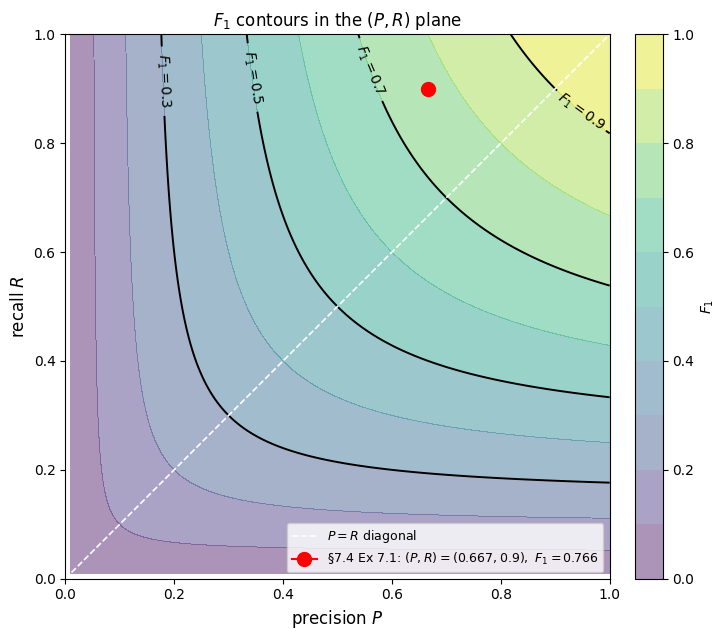

Sanity check vs §7.4 Example 7.1 (fpr=0.05, fnr=0.10, pi=0.10):
  precision = 0.6667 (book: 2/3)
  recall    = 0.9000
  F1        = 0.7660  (book: ~0.766)


In [7]:
p_grid = np.linspace(0.01, 1.0, 300)
r_grid = np.linspace(0.01, 1.0, 300)
P, R = np.meshgrid(p_grid, r_grid)
F1 = 2.0 * P * R / (P + R)

fig, ax = plt.subplots(figsize=(7.5, 6.5))
levels = [0.3, 0.5, 0.7, 0.9]
filled = ax.contourf(P, R, F1, levels=np.linspace(0.0, 1.0, 11),
                     cmap="viridis", alpha=0.45)
cs = ax.contour(P, R, F1, levels=levels, colors="black", linewidths=1.4)
ax.clabel(cs, fmt="$F_1=%.1f$", fontsize=10)
ax.plot([0, 1], [0, 1], color="white", linestyle="--", linewidth=1.2,
        label=r"$P = R$ diagonal")

# Mark the (P, R) point from §7.4 Example 7.1: F1 ~ 0.766 at P ~ 0.667, R = 0.9.
P_ex = 2.0 / 3.0
R_ex = 0.9
F1_ex = 2.0 * P_ex * R_ex / (P_ex + R_ex)
ax.plot([P_ex], [R_ex], marker="o", color="red", markersize=10,
        label=fr"§7.4 Ex 7.1: $(P, R) = ({P_ex:.3f}, {R_ex}),\ F_1 = {F1_ex:.3f}$")

ax.set_xlabel(r"precision $P$", fontsize=12)
ax.set_ylabel(r"recall $R$", fontsize=12)
ax.set_title(r"$F_1$ contours in the $(P, R)$ plane", fontsize=12)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_aspect("equal")
ax.legend(fontsize=9, loc="lower right")
fig.colorbar(filled, ax=ax, fraction=0.045, pad=0.04, label=r"$F_1$")
plt.tight_layout()
plt.show()

# Sanity check from §7.4 Example 7.1.
print("Sanity check vs §7.4 Example 7.1 (fpr=0.05, fnr=0.10, pi=0.10):")
print(f"  precision = {P_ex:.4f} (book: 2/3)")
print(f"  recall    = {R_ex:.4f}")
print(f"  F1        = {F1_ex:.4f}  (book: ~0.766)")

## 7. Bloom Filter Diagnostic (replicating §7.5)

The chapter 7 §7.5 worked application has a deployed Bloom filter with $(m, k, n) = (50000, 7, 5000)$ on a workload of $N = 10000$ messages. The empirical observation: $n_\top = 1000$ spam, $n_\bot = 9000$ not, $\mathrm{FP} = 92$, so $\hat{\fprate} = 92/9000 \approx 0.01022$ and prevalence $\hat\pi = 0.1$. The filter has $\fnrate = 0$ by construction.

We compute:

1. The Wilson $95\%$ CI for $\fprate$ from the empirical $92 / 9000$.
2. The point estimate of PPV at $(\hat{\fprate}, \hat\pi)$.
3. The delta-method $95\%$ CI for PPV using Proposition 7.5.
4. The two operational routes from §7.5: lower $\fprate$ to $0.005$ vs raise $\pi$ to $0.2$.

In [8]:
BLOOM_FP = 92
BLOOM_NBOT = 9000
BLOOM_NTOP = 1000
BLOOM_PI = BLOOM_NTOP / (BLOOM_NTOP + BLOOM_NBOT)

fpr_hat_bloom = BLOOM_FP / BLOOM_NBOT
lo_w, hi_w = wilson_ci(np.array([BLOOM_FP]), BLOOM_NBOT)
print("§7.5 Bloom filter diagnostic:")
print(f"  fpr_hat                  = {fpr_hat_bloom:.5f}     (book: ~0.01022)")
print(f"  Wilson 95% CI for fpr    = [{lo_w[0]:.5f}, {hi_w[0]:.5f}]   (book: [0.00834, 0.01253])")
print()

# Point estimate of PPV at empirical rates and prevalence.
fnr_hat_bloom = 0.0
ppv_point = ppv_of(np.array([BLOOM_PI]), fpr_hat_bloom, fnr_hat_bloom)[0]
print(f"  PPV point estimate       = {ppv_point:.4f}        (book: ~0.916)")

# Delta-method CI for PPV using Prop 7.5 plug-in.
var_ppv = ppv_delta_var(BLOOM_NTOP, BLOOM_NBOT, fpr_hat_bloom, fnr_hat_bloom)
se_ppv = float(np.sqrt(var_ppv))
ppv_lo_bloom = ppv_point - Z_95 * se_ppv
ppv_hi_bloom = ppv_point + Z_95 * se_ppv
print(f"  delta-method Var[PPV]    = {var_ppv:.6e}")
print(f"  delta-method SE          = {se_ppv:.5f}")
print(f"  delta-method 95% CI      = [{ppv_lo_bloom:.4f}, {ppv_hi_bloom:.4f}]   (book: [0.900, 0.932])")
print()

# Diagnostic routes from §7.5.
ppv_routeA = ppv_of(np.array([BLOOM_PI]), 0.005, 0.0)[0]
ppv_routeB = ppv_of(np.array([0.2]), fpr_hat_bloom, 0.0)[0]
print("Route A: lower fpr to 0.005, keep prevalence at 0.1")
print(f"  PPV = {ppv_routeA:.4f}  (book: ~0.957)")
print("Route B: keep fpr at 0.01022, wait for prevalence to climb to 0.2")
print(f"  PPV = {ppv_routeB:.4f}  (book: ~0.961)")
print()
print("Both routes clear the 0.95 operational target. The choice between them")
print("is operational rather than statistical: route A spends storage capital")
print("to enlarge the bit array, route B accepts the current PPV until the")
print("workload's prevalence drifts upward on its own.")

§7.5 Bloom filter diagnostic:
  fpr_hat                  = 0.01022     (book: ~0.01022)
  Wilson 95% CI for fpr    = [0.00834, 0.01252]   (book: [0.00834, 0.01253])

  PPV point estimate       = 0.9158        (book: ~0.916)
  delta-method Var[PPV]    = 6.403759e-05
  delta-method SE          = 0.00800
  delta-method 95% CI      = [0.9001, 0.9314]   (book: [0.900, 0.932])

Route A: lower fpr to 0.005, keep prevalence at 0.1
  PPV = 0.9569  (book: ~0.957)
Route B: keep fpr at 0.01022, wait for prevalence to climb to 0.2
  PPV = 0.9607  (book: ~0.961)

Both routes clear the 0.95 operational target. The choice between them
is operational rather than statistical: route A spends storage capital
to enlarge the bit array, route B accepts the current PPV until the
workload's prevalence drifts upward on its own.


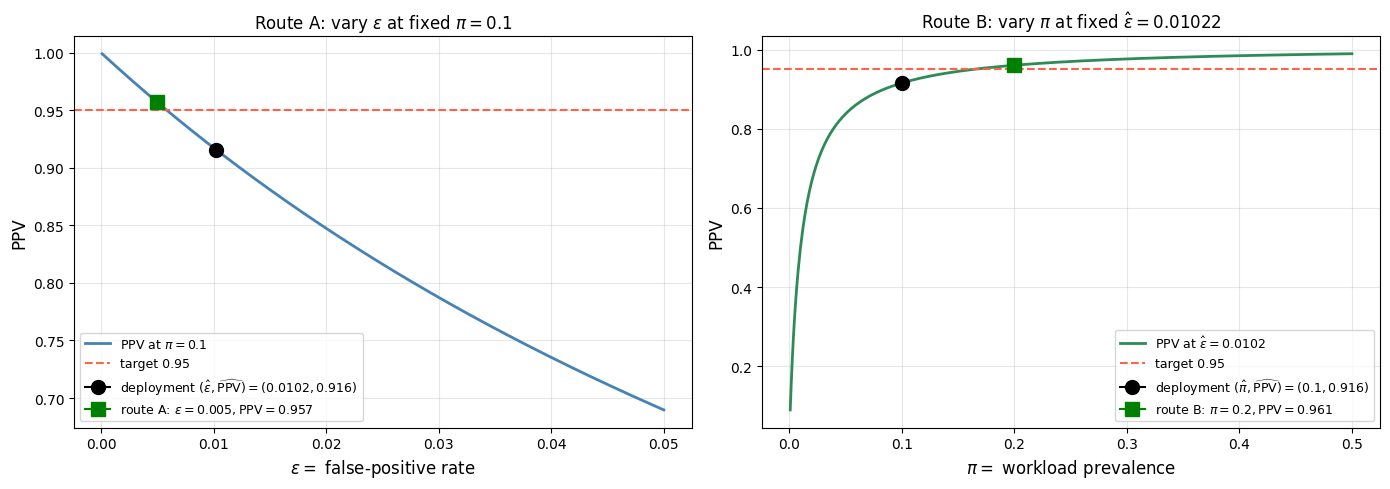

In [9]:
# Visualize the diagnostic: PPV as a function of fpr at fixed prevalence,
# and PPV as a function of prevalence at fixed fpr, both passing through the
# observed deployment point.
fpr_axis = np.linspace(0.0001, 0.05, 500)
ppv_vs_fpr = ppv_of(np.full_like(fpr_axis, BLOOM_PI), fpr_axis, 0.0)

pi_axis = np.linspace(0.001, 0.5, 500)
ppv_vs_pi = ppv_of(pi_axis, fpr_hat_bloom, 0.0)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(fpr_axis, ppv_vs_fpr, color="steelblue", linewidth=2,
             label=rf"PPV at $\pi = {BLOOM_PI}$")
axes[0].axhline(0.95, color="tomato", linestyle="--", linewidth=1.5,
                label="target 0.95")
axes[0].plot([fpr_hat_bloom], [ppv_point], marker="o", color="black", markersize=10,
             label=fr"deployment $(\hat\epsilon, \widehat{{\mathrm{{PPV}}}}) = ({fpr_hat_bloom:.4f}, {ppv_point:.3f})$")
axes[0].plot([0.005], [ppv_routeA], marker="s", color="green", markersize=10,
             label=fr"route A: $\epsilon = 0.005, \mathrm{{PPV}} = {ppv_routeA:.3f}$")
axes[0].set_xlabel(r"$\epsilon = $ false-positive rate", fontsize=12)
axes[0].set_ylabel(r"PPV", fontsize=12)
axes[0].set_title(r"Route A: vary $\epsilon$ at fixed $\pi = 0.1$", fontsize=12)
axes[0].legend(fontsize=9, loc="lower left")
axes[0].grid(True, alpha=0.3)

axes[1].plot(pi_axis, ppv_vs_pi, color="seagreen", linewidth=2,
             label=rf"PPV at $\hat\epsilon = {fpr_hat_bloom:.4f}$")
axes[1].axhline(0.95, color="tomato", linestyle="--", linewidth=1.5,
                label="target 0.95")
axes[1].plot([BLOOM_PI], [ppv_point], marker="o", color="black", markersize=10,
             label=fr"deployment $(\hat\pi, \widehat{{\mathrm{{PPV}}}}) = ({BLOOM_PI}, {ppv_point:.3f})$")
axes[1].plot([0.2], [ppv_routeB], marker="s", color="green", markersize=10,
             label=fr"route B: $\pi = 0.2, \mathrm{{PPV}} = {ppv_routeB:.3f}$")
axes[1].set_xlabel(r"$\pi = $ workload prevalence", fontsize=12)
axes[1].set_ylabel(r"PPV", fontsize=12)
axes[1].set_title(r"Route B: vary $\pi$ at fixed $\hat\epsilon = 0.01022$", fontsize=12)
axes[1].legend(fontsize=9, loc="lower right")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 8. The Diagnostic-Testing Tension

The prevalence-dependence of PPV is the central tension the medical diagnostic-testing community has wrestled with for a century, and it bites every approximate-set deployment in the same way. The classifier vendor's claim is naturally $(\fprate, \fnrate)$: those are intrinsic and reproducible properties of the noisy bit. The downstream user wants PPV: how often does a $\top$-report mean the underlying truth is actually $\top$? That is a property of the classifier *and* the workload it sees. Two users with the same classifier and different workloads will quote different PPV numbers, and both will be correct.

What chapter 7 has added on top of chapter 1: an honest treatment of uncertainty. The chapter 1 notebook ended at the point estimate, with a Wald interval that does not honestly cover. Chapter 7 §7.3 gave Wilson, Clopper-Pearson, and Jeffreys as the working replacements; §7.4 carried the same treatment through to derived measures via the delta method. The Bloom filter diagnostic in §7.5 (replicated in §7 above) showed the practical payoff: a point estimate of $\widehat{\PPV} \approx 0.916$ alone would have suggested the operational target $0.95$ was within reach, while the interval $[0.900, 0.932]$ rules out $0.95$ at $95\%$ confidence. The fix is not a small tweak; it is a structural change to the filter or to the workload.

**What stays open.** The delta method assumes the empirical rates $\hat{\fprate}, \hat{\fnrate}, \hat\pi$ are jointly asymptotically Normal, an assumption that fails near the boundary of the unit cube. The §7.4 closing paragraph noted that a Wilson-on-the-conditional-binomial construction (treating $\TP$ as binomial given $\TP + \FP$) is the boundary-safe alternative; chapter 8 picks up where this leaves off when the rates themselves become information-theoretic quantities tied to entropy. Chapter 14 returns to the diagnostic question with a different tool: perfect-hash filters whose $\fprate$ is bounded by construction, removing the need for the empirical-rate estimate in the first place.

**The deferral chapter 1 §1.4 named is now retired in full.** Item (i) (estimator properties): §7.2. Item (ii) (proper CIs): §7.3. Item (iii) (sawtooth coverage failure): §7.3 with exact-coverage diagnosis above. Item (iv) (derived measures): §7.4 with delta-method machinery. The remainder of Part II builds the algebra of approximate sets, maps, and relations on top of the rate-estimation toolkit assembled here.

---

## Closing: Cross-References and Next Steps

**Chapter 7** retires the chapter 1 §1.4 deferral on rate estimation: properties of the binomial estimator (§7.2), Wald / Wilson / Clopper-Pearson / Jeffreys confidence intervals (§7.3), the prevalence-dependent derived measures PPV / NPV / $\Fone$ (§7.4), and the Bloom filter diagnostic application (§7.5).

**Chapter 6** (Set Composition) is the predecessor: it stated how $(\fprate, \fnrate)$ compose under set operations. Chapter 7 says how to estimate $(\fprate, \fnrate)$ in the first place and how to read PPV off that estimate at deployment prevalence.

**Chapter 8** (Entropy and Space Complexity, forthcoming) ties the rate-estimation question to the information-theoretic lower bound on filter size, picking up where §7.5's diagnostic question left off.

**Chapter 14** (Perfect-Hash Filters) gives a construction whose $\fprate$ is bounded by design, removing the empirical-rate estimation step that chapter 7 wrestled with.

**Summary of what this notebook verified:**

| Section | Claim | Verified |
|---------|-------|----------|
| §7.3 sawtooth | Wald exact coverage oscillates and under-covers at $\fprate = 0.05$, $n_0 \in [10, 200]$ | Yes (exact enumeration) |
| §7.3 Wilson | Wilson exact coverage tracks $0.95$ cleanly | Yes |
| §7.3 Clopper-Pearson | Clopper-Pearson over-covers ($\geq 0.95$ by construction) | Yes |
| §7.3 Jeffreys | Jeffreys is near-nominal on average | Yes |
| §7.4 PPV as random variable | Empirical distribution of $\widehat{\PPV}$ over 1000 simulations centers on the true PPV | Yes |
| §7.4 Prop 7.5 delta-method CI | Empirical coverage near $0.95$ at $(0.05, 0.10, 0.20, 500)$ | Yes |
| §7.4 prevalence sweep | PPV bends sharply near $\pi = 0$; NPV bends sharply near $\pi = 1$ | Yes |
| §7.4 $\Fone$ contours | Convex level curves in the $(P, R)$ plane | Yes |
| §7.5 Bloom diagnostic | $\widehat{\PPV} \approx 0.916$, Wilson and delta-method CIs match book numbers | Yes |